# Importando bibliotecas

In [46]:
# Manipulação e análise de dados
import pandas as pd
import numpy as np

# Extração e localização de arquivos
import zipfile
import os

# Visualização de dados
import matplotlib.pyplot as plt

# Divisão dos conjuntos de dados
from sklearn.model_selection import train_test_split

# Pré-processamento
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelo de classificação
from sklearn.ensemble import RandomForestClassifier

# Métricas de avaliação
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


# Extração dos arquivos

In [47]:
# Caminhos do arquivo ZIP e da pasta de extração
zip_path = "/car+evaluation.zip"
extract_path = "/content/car_evaluation"

# Extração dos arquivos
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Exibição dos arquivos extraídos
print("Arquivos extraídos:")
print(os.listdir(extract_path))

Arquivos extraídos:
['car.c45-names', 'car.data', 'car.names']


# Carregamento dos dados

In [48]:
# Definição dos nomes das colunas
columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

# Carregamento do dataset
df = pd.read_csv(
    os.path.join(extract_path, "car.data"),
    header=None,
    names=columns,
    dtype=str
)

# Exibição dos cinco primeiros registros
display(df.head())

# Dimensões do dataset
print("Dimensões do dataset:", df.shape)

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


Dimensões do dataset: (1728, 7)


# Informações gerais do dataset

In [49]:
# Informações gerais do dataset
print("Quantidade de registros:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

# Estrutura e tipos de dados
df.info()

Quantidade de registros: 1728
Quantidade de colunas: 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


# Estatísticas descritivas

In [50]:
# Estatísticas descritivas dos atributos categóricos
display(df.describe(include="all"))

,buying,maint,doors,persons,lug_boot,safety,class
count,1728,1728,1728,1728,1728,1728,1728
unique,4,4,4,3,3,3,4
top,vhigh,vhigh,2,2,small,low,unacc
freq,432,432,432,576,576,576,1210


# Valores ausentes e duplicados

In [51]:
# Verificação de valores ausentes
print("Valores ausentes por coluna:")
print(df.isnull().sum())

# Verificação de registros duplicados
print("\nRegistros duplicados:", df.duplicated().sum())

Valores ausentes por coluna:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Registros duplicados: 0


# Valores distintos por atributo

In [52]:
# Identificação das categorias de cada coluna
for column in df.columns:
    print(f"{column}: {df[column].unique().tolist()}")

buying: ['vhigh', 'high', 'med', 'low']
maint: ['vhigh', 'high', 'med', 'low']
doors: ['2', '3', '4', '5more']
persons: ['2', '4', 'more']
lug_boot: ['small', 'med', 'big']
safety: ['low', 'med', 'high']
class: ['unacc', 'acc', 'vgood', 'good']


# Distribuição da variável-alvo

In [53]:
# Quantidade e percentual de registros por classe
class_distribution = pd.DataFrame({
    "Quantidade": df["class"].value_counts(),
    "Percentual (%)": (
        df["class"].value_counts(normalize=True) * 100
    ).round(2)
})

display(class_distribution)

,Quantidade,Percentual (%)
class,,
unacc,1210,70.02
acc,384,22.22
good,69,3.99
vgood,65,3.76


# Visualização gráfica das classes

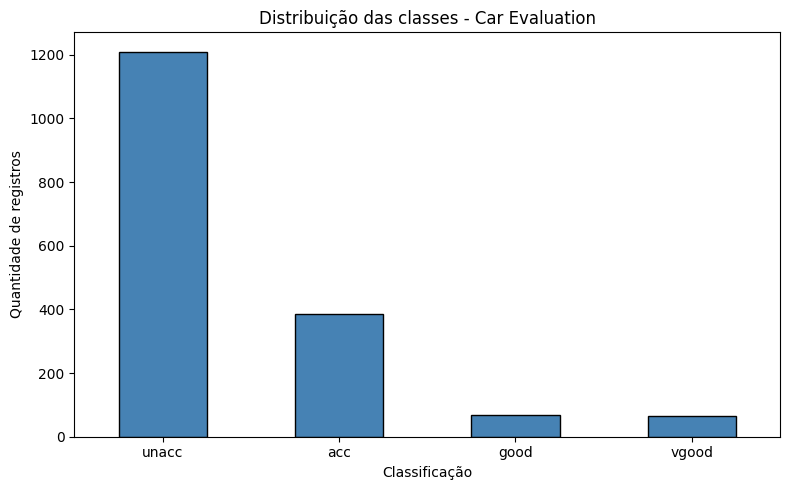

In [54]:
# Gráfico de distribuição das classes
df["class"].value_counts().plot(
    kind="bar",
    color="steelblue",
    edgecolor="black",
    figsize=(8, 5)
)

plt.title("Distribuição das classes - Car Evaluation")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Cópia do dataset original

In [55]:
# Criação de uma cópia do dataset
df_processed = df.copy()

print("Dataset copiado com sucesso!")

Dataset copiado com sucesso!


# Transformação das colunas

In [56]:
# Mapeamento das classes para valores numéricos
class_mapping = {
    "unacc": 0,
    "acc": 1,
    "good": 2,
    "vgood": 3
}

# Transformação da variável-alvo
df_processed["class"] = (
    df_processed["class"].map(class_mapping)
)

# Validação da transformação
assert df_processed["class"].notna().all()

df_processed["class"] = df_processed["class"].astype(int)

display(df_processed.head())

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,0
1,vhigh,vhigh,2,2,small,med,0
2,vhigh,vhigh,2,2,small,high,0
3,vhigh,vhigh,2,2,med,low,0
4,vhigh,vhigh,2,2,med,med,0


# Transformação das linhas

In [57]:
# Embaralhamento dos registros
df_processed = df_processed.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Visualização dos registros após o embaralhamento
display(df_processed.head(10))

,buying,maint,doors,persons,lug_boot,safety,class
0,high,high,4,2,med,high,0
1,med,low,2,4,med,med,1
2,high,high,5more,2,big,med,0
3,low,high,5more,4,med,med,1
4,med,low,4,more,med,low,0
5,med,vhigh,4,4,med,med,1
6,vhigh,vhigh,2,more,med,high,0
7,high,low,5more,2,big,med,0
8,med,vhigh,5more,more,small,med,0
9,high,low,2,2,big,high,0


# Validação das transformações

In [58]:
# Validação da integridade dos dados
print("Dimensões originais:", df.shape)
print("Dimensões após transformação:", df_processed.shape)

print("\nValores ausentes:", df_processed.isnull().sum().sum())
print("Registros duplicados:", df_processed.duplicated().sum())

print("\nDistribuição das classes após transformação:")
print(df_processed["class"].value_counts().sort_index())

print("\nTipos de dados:")
print(df_processed.dtypes)

Dimensões originais: (1728, 7)
Dimensões após transformação: (1728, 7)

Valores ausentes: 0
Registros duplicados: 0

Distribuição das classes após transformação:
class
0    1210
1     384
2      69
3      65
Name: count, dtype: int64

Tipos de dados:
buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class        int64
dtype: object


# Separação dos atributos e da variável-alvo

In [59]:
# Atributos de entrada
X = df_processed.drop(columns=["class"])

# Variável-alvo
y = df_processed["class"]

print("Dimensões dos atributos:", X.shape)
print("Dimensões da variável-alvo:", y.shape)

Dimensões dos atributos: (1728, 6)
Dimensões da variável-alvo: (1728,)


# Divisão dos conjuntos de dados

In [60]:
# Separação do conjunto de treinamento (70%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Separação dos conjuntos de validação e teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Verificação dos conjuntos

In [61]:
# Quantidade de registros em cada conjunto
print("Treinamento:", len(X_train))
print("Validação:", len(X_val))
print("Teste:", len(X_test))

# Validação da quantidade total
total = len(X_train) + len(X_val) + len(X_test)

assert total == len(df_processed)

print("\nTotal de registros:", total)

Treinamento: 1209
Validação: 259
Teste: 260

Total de registros: 1728


# Verificação da distribuição das classes

In [62]:
# Comparação percentual das classes entre os conjuntos
distribution = pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True) * 100,
    "Treinamento (%)": y_train.value_counts(normalize=True) * 100,
    "Validação (%)": y_val.value_counts(normalize=True) * 100,
    "Teste (%)": y_test.value_counts(normalize=True) * 100
})

# Organização e identificação das classes
distribution = distribution.sort_index().rename(index={
    0: "unacc",
    1: "acc",
    2: "good",
    3: "vgood"
})

display(distribution.round(2))

,Original (%),Treinamento (%),Validação (%),Teste (%)
class,,,,
unacc,70.02,70.06,69.88,70.00
acc,22.22,22.25,22.01,22.31
good,3.99,3.97,4.25,3.85
vgood,3.76,3.72,3.86,3.85


# Verificação de independência dos conjuntos

In [63]:
# Verificação de sobreposição entre os conjuntos
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("Conjuntos independentes e validados com sucesso!")

Conjuntos independentes e validados com sucesso!


# Identificação das colunas categóricas

In [64]:
# Identificação das colunas categóricas
categorical_features = X_train.columns.tolist()

print("Atributos categóricos:")
print(categorical_features)

Atributos categóricos:
['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']


# Codificação das variáveis categóricas

In [65]:
# Configuração do codificador categórico
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

print("Codificador categórico configurado!")

Codificador categórico configurado!


# Configuração do pré-processador

In [66]:
# Configuração do pré-processador
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Pré-processador configurado com sucesso!")

Pré-processador configurado com sucesso!


# Configuração do modelo

In [67]:
# Configuração do modelo Random Forest
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

print("Modelo Random Forest configurado!")

Modelo Random Forest configurado!


# Configuração da Pipeline

In [68]:
# Construção da esteira de aprendizado de máquina
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", model)
])

print("Pipeline configurada com sucesso!")

Pipeline configurada com sucesso!


# Treinamento do modelo

In [69]:
# Treinamento da Pipeline
pipeline.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


# Verificação do modelo treinado

In [70]:
# Acesso ao classificador treinado
trained_model = pipeline.named_steps["classifier"]

# Informações do modelo
print("Quantidade de árvores:", len(trained_model.estimators_))
print("Quantidade de classes:", trained_model.n_classes_)
print("Classes identificadas:", trained_model.classes_)
print("Atributos após pré-processamento:", trained_model.n_features_in_)
print("Registros utilizados no treinamento:", len(X_train))

Quantidade de árvores: 300
Quantidade de classes: 4
Classes identificadas: [0 1 2 3]
Atributos após pré-processamento: 21
Registros utilizados no treinamento: 1209


# Realização das previsões

In [71]:
# Predições do conjunto de validação
y_val_pred = pipeline.predict(X_val)

print("Predições realizadas:", len(y_val_pred))

# Exibição das primeiras 10 previsões
print("Primeiras previsões:", y_val_pred[:10])

Predições realizadas: 259
Primeiras previsões: [1 0 0 0 1 0 0 3 0 1]


# Cálculo da acurácia

In [72]:
# Cálculo da acurácia de validação
val_accuracy = accuracy_score(y_val, y_val_pred)

# Quantidade de classificações corretas e incorretas
val_correct = (y_val == y_val_pred).sum()
val_incorrect = (y_val != y_val_pred).sum()

print(f"Acurácia de validação: {val_accuracy:.2%}")
print("Classificações corretas:", val_correct)
print("Classificações incorretas:", val_incorrect)

Acurácia de validação: 96.91%
Classificações corretas: 251
Classificações incorretas: 8


# Relatório de classificação

In [73]:
# Nomes das classes
class_names = ["unacc", "acc", "good", "vgood"]

# Relatório de classificação
print("Relatório de classificação - Validação\n")

print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    digits=4,
    zero_division=0
))

Relatório de classificação - Validação

              precision    recall  f1-score   support

       unacc     1.0000    0.9779    0.9888       181
         acc     0.9322    0.9649    0.9483        57
        good     0.8182    0.8182    0.8182        11
       vgood     0.8333    1.0000    0.9091        10

    accuracy                         0.9691       259
   macro avg     0.8959    0.9402    0.9161       259
weighted avg     0.9709    0.9691    0.9696       259



# Comparação com uma classificação de referência

In [74]:
# Identificação da classe majoritária no treinamento
majority_class = y_train.mode()[0]

# Predições utilizando apenas a classe majoritária
baseline_pred = np.full(len(y_val), majority_class)

# Acurácia de referência
baseline_accuracy = accuracy_score(y_val, baseline_pred)

print(f"Acurácia de referência: {baseline_accuracy:.2%}")
print(f"Acurácia do Random Forest: {val_accuracy:.2%}")

print(
    f"Diferença: "
    f"{(val_accuracy - baseline_accuracy) * 100:.2f} "
    "pontos percentuais"
)

Acurácia de referência: 69.88%
Acurácia do Random Forest: 96.91%
Diferença: 27.03 pontos percentuais


# Avaliação final com dados de teste

In [75]:
# Predições do conjunto de teste
y_test_pred = pipeline.predict(X_test)

print("Predições realizadas:", len(y_test_pred))

# Exibição das primeiras 10 previsões
print("Primeiras previsões:", y_test_pred[:10])

Predições realizadas: 260
Primeiras previsões: [0 0 0 0 1 0 1 2 3 0]


# Cálculo da acurácia de teste

In [76]:
# Cálculo da acurácia de teste
test_accuracy = accuracy_score(y_test, y_test_pred)

# Quantidade de classificações corretas e incorretas
test_correct = (y_test == y_test_pred).sum()
test_incorrect = (y_test != y_test_pred).sum()

print(f"Acurácia de teste: {test_accuracy:.2%}")
print("Classificações corretas:", test_correct)
print("Classificações incorretas:", test_incorrect)

Acurácia de teste: 96.54%
Classificações corretas: 251
Classificações incorretas: 9


# Relatório de classificação

In [77]:
# Relatório de classificação do conjunto de teste
print("Relatório de classificação - Teste\n")

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    digits=4,
    zero_division=0
))

Relatório de classificação - Teste

              precision    recall  f1-score   support

       unacc     1.0000    0.9725    0.9861       182
         acc     0.9180    0.9655    0.9412        58
        good     0.7500    0.9000    0.8182        10
       vgood     0.9000    0.9000    0.9000        10

    accuracy                         0.9654       260
   macro avg     0.8920    0.9345    0.9114       260
weighted avg     0.9683    0.9654    0.9663       260



# Comparação entre validação e teste

In [78]:
# Comparação dos resultados
results = pd.DataFrame({
    "Conjunto": ["Validação", "Teste"],
    "Registros": [len(y_val), len(y_test)],
    "Acertos": [val_correct, test_correct],
    "Erros": [val_incorrect, test_incorrect],
    "Acurácia (%)": [
        round(val_accuracy * 100, 2),
        round(test_accuracy * 100, 2)
    ]
})

display(results)

# Diferença entre as acurácias
difference = (test_accuracy - val_accuracy) * 100

print(f"Diferença (teste - validação): {difference:.2f} p.p.")

,Conjunto,Registros,Acertos,Erros,Acurácia (%)
0,Validação,259,251,8,96.91
1,Teste,260,251,9,96.54


Diferença (teste - validação): -0.37 p.p.


# Visualização comparativa

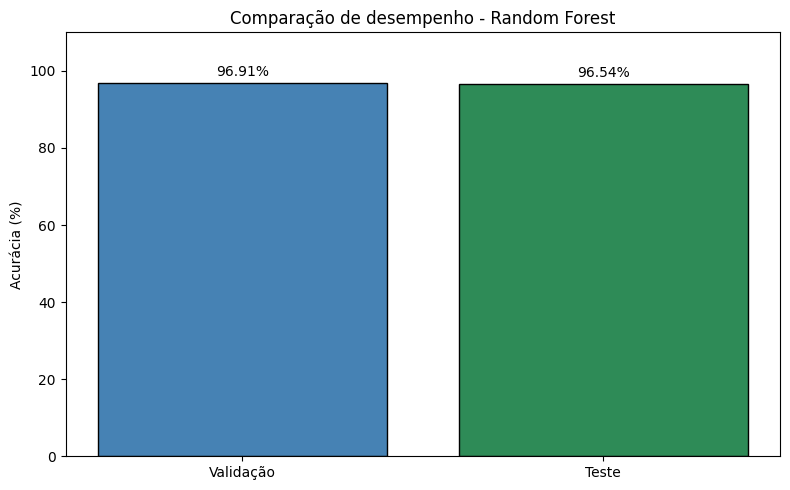

In [79]:
# Gráfico comparativo das acurácias
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Validação", "Teste"],
    [val_accuracy * 100, test_accuracy * 100],
    color=["steelblue", "seagreen"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.title("Comparação de desempenho - Random Forest")
plt.ylabel("Acurácia (%)")
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

# Matriz de confusão

In [80]:
# Geração da matriz de confusão
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3]
)

# Organização da matriz em um DataFrame
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("Matriz de confusão - Conjunto de teste")
display(cm_df)

Matriz de confusão - Conjunto de teste


,unacc,acc,good,vgood
unacc,177,4,1,0
acc,0,56,1,1
good,0,1,9,0
vgood,0,0,1,9


# Visualização gráfica

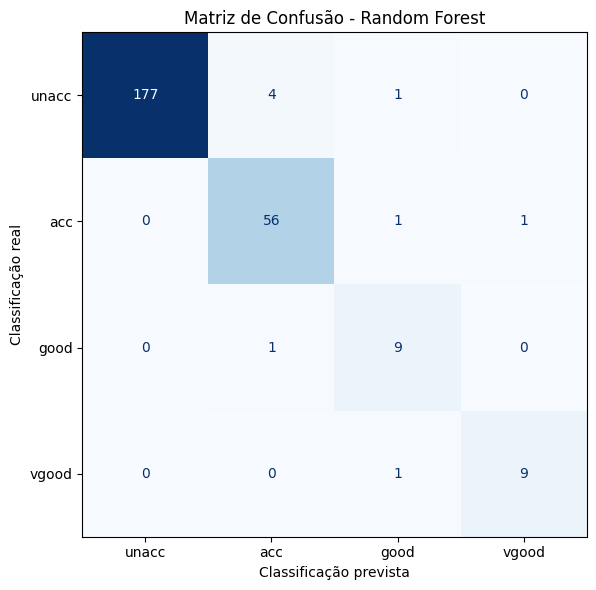

In [81]:
# Configuração da visualização
fig, ax = plt.subplots(figsize=(8, 6))

# Exibição da matriz de confusão
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Matriz de Confusão - Random Forest")
plt.xlabel("Classificação prevista")
plt.ylabel("Classificação real")
plt.tight_layout()
plt.show()

# Validação dos resultados

In [82]:
# Total de classificações corretas
correct_predictions = np.trace(cm)

# Total de classificações incorretas
incorrect_predictions = cm.sum() - correct_predictions

# Acurácia calculada pela matriz
cm_accuracy = correct_predictions / cm.sum()

print("Total de classificações:", cm.sum())
print("Classificações corretas:", correct_predictions)
print("Classificações incorretas:", incorrect_predictions)
print(f"Acurácia: {cm_accuracy:.2%}")

# Validação da consistência dos resultados
assert correct_predictions == test_correct
assert incorrect_predictions == test_incorrect
assert np.isclose(cm_accuracy, test_accuracy)

print("\nMatriz de confusão validada com sucesso!")

Total de classificações: 260
Classificações corretas: 251
Classificações incorretas: 9
Acurácia: 96.54%

Matriz de confusão validada com sucesso!


# Predição individual

In [83]:
# Seleção de um registro do conjunto de teste
sample_index = 0

sample = X_test.iloc[[sample_index]]
actual_class = y_test.iloc[sample_index]

# Exibição dos atributos do veículo
print("Características do veículo:")
display(sample)

Características do veículo:


,buying,maint,doors,persons,lug_boot,safety
1462,vhigh,high,3,4,small,high


# Realização da predição

In [84]:
# Predição individual
prediction = pipeline.predict(sample)[0]

# Probabilidades estimadas para cada classe
probabilities = pipeline.predict_proba(sample)[0]

# Descrição das classes
class_descriptions = {
    0: "Inaceitável",
    1: "Aceitável",
    2: "Bom",
    3: "Muito bom"
}

# Exibição do resultado
print("Classificação real:", class_descriptions[actual_class])
print("Classificação prevista:", class_descriptions[prediction])

print(
    "Resultado:",
    "Correto" if prediction == actual_class else "Incorreto"
)

Classificação real: Inaceitável
Classificação prevista: Inaceitável
Resultado: Correto


# Probabilidades estimadas

In [85]:
# Organização das probabilidades por classe
prediction_results = pd.DataFrame({
    "Classe": [
        class_descriptions[c]
        for c in pipeline.classes_
    ],
    "Probabilidade (%)": (
        probabilities * 100
    ).round(2)
})

display(prediction_results)

,Classe,Probabilidade (%)
0,Inaceitável,71.33
1,Aceitável,28.67
2,Bom,0.00
3,Muito bom,0.00


# Visualização gráfica da predição

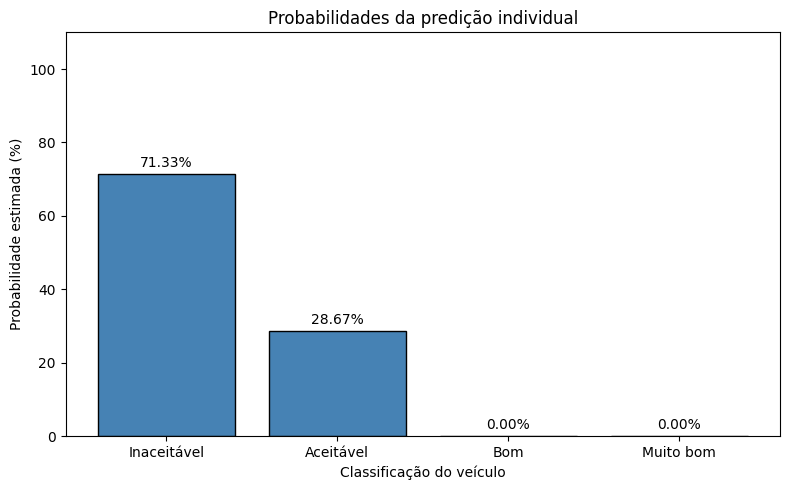

In [86]:
# Gráfico das probabilidades estimadas
plt.figure(figsize=(8, 5))

bars = plt.bar(
    prediction_results["Classe"],
    prediction_results["Probabilidade (%)"],
    color="steelblue",
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Probabilidades da predição individual")
plt.xlabel("Classificação do veículo")
plt.ylabel("Probabilidade estimada (%)")
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

# Predição de um novo veículo

In [89]:
# Características de um novo veículo
new_car = pd.DataFrame([{
    "buying": "low",
    "maint": "low",
    "doors": "4",
    "persons": "4",
    "lug_boot": "big",
    "safety": "high"
}])

# Predição do novo veículo
new_prediction = pipeline.predict(new_car)[0]
new_probabilities = pipeline.predict_proba(new_car)[0]

print("Características do veículo:")
display(new_car)

print(
    "Classificação prevista:",
    class_descriptions[new_prediction]
)

# Exibição das probabilidades
display(pd.DataFrame({
    "Classe": [
        class_descriptions[c]
        for c in pipeline.classes_
    ],
    "Probabilidade (%)": (
        new_probabilities * 100
    ).round(2)
}))

Características do veículo:


,buying,maint,doors,persons,lug_boot,safety
0,low,low,4,4,big,high


Classificação prevista: Muito bom


,Classe,Probabilidade (%)
0,Inaceitável,4.00
1,Aceitável,3.67
2,Bom,0.67
3,Muito bom,91.67
